In [1]:
import pandas as pd

df_site = pd.read_csv("/Users/aditiiyer/Documents/Thesis/data_sg_filter.csv")

In [2]:
df_site = df_site.drop(['Unnamed: 0'], axis = 1)

In [3]:
df_field = pd.read_csv("/Users/aditiiyer/Documents/Thesis/2024_data_reduced.csv")

In [4]:
df1 = df_field.copy()

In [5]:
import numpy as np
import pandas as pd

usda_vertices = {
    "Sand": [(100,0,0),(90,10,0),(85,15,0),(100,0,0)],
    "Loamy Sand": [(90,10,0),(85,15,0),(70,30,0),(75,10,15),(90,10,0)],
    "Sandy Loam": [(70,30,0),(52,48,0),(52,28,20),(45,27,28),(50,0,50),(75,10,15),(70,30,0)],
    "Loam": [(52,28,20),(28,44,28),(22,28,50),(40,20,40),(43,34,23),(45,27,28),(52,28,20)],
    "Silt Loam": [(20,80,0),(0,100,0),(0,88,12),(8,42,50),(28,22,50),(28,44,28),(52,28,20),(43,34,23),(40,20,40),(22,28,50),(20,80,0)],
    "Silt": [(0,100,0),(0,88,12),(0,100,0)],
    "Sandy Clay Loam": [(45,27,28),(43,34,23),(65,35,0),(52,48,0),(52,28,20),(45,27,28)],
    "Clay Loam": [(28,44,28),(22,28,50),(40,20,40),(47,13,40),(55,25,20),(43,34,23),(28,44,28)],
    "Silty Clay Loam": [(28,22,50),(22,28,50),(0,50,50),(0,60,40),(8,42,50),(28,22,50)],
    "Sandy Clay": [(65,35,0),(55,45,0),(45,35,20),(55,25,20),(65,35,0)],
    "Silty Clay": [(0,60,40),(0,88,12),(8,42,50),(0,60,40)],
    "Clay": [(55,45,0),(45,35,20),(40,20,40),(47,13,40),(55,25,20),(55,45,0)]
}

def ternary_centroid(coords):
    arr = np.array(coords, dtype=float)
    c = arr.mean(axis=0)
    s = c.sum()
    if s != 0:
        c = c / s * 100
    return tuple(c)

centroids = {k: ternary_centroid(v) for k, v in usda_vertices.items()}

centroid_df = pd.DataFrame.from_dict(
    centroids,
    orient="index",
    columns=["sand_centroid","silt_centroid","clay_centroid"]
)

# soil_texture column must match centroid keys exactly; normalize if needed
df_field["soil_texture"] = df_field["soil_texture"].str.strip().str.title()

df = df_field.merge(
    centroid_df,
    left_on="soil_texture",
    right_index=True,
    how="left"
)

df1 = df.drop(columns=["soil_texture"])


In [6]:
import re
import pandas as pd

def parse_munsell_hvc(x):
    if pd.isna(x):
        return (None, None, None)
    s = str(x).replace(',', '.')
    s = s.split(';')[0].strip()
    m = re.match(r'([0-9\.]+)([A-Z]+)([0-9\.]+)/([0-9\.]+)', s)
    if m:
        hue_num = float(m.group(1))
        hue_sym = m.group(2)
        val = float(m.group(3))
        chroma = float(m.group(4))
        hue_map = {'R':0,'YR':10,'Y':20,'GY':30,'G':40,'BG':50,'B':60,'PB':70,'P':80,'RP':90}
        h = hue_num + hue_map.get(hue_sym, 0)
        return (h, val, chroma)
    return (None, None, None)

df1 = df1.copy()
df1[['H','V','C']] = df1['soil_color'].apply(parse_munsell_hvc).apply(pd.Series)


In [7]:
df1.head()

,Unnamed: 0,Date,time,latitude,longitude,soil_moisture,soil_color,BD_inc_roots,TOC_percent,sand_centroid,silt_centroid,clay_centroid,H,V,C
0,0,2024-08-19,17:11:00,33.362800,78.013930,76.20,5Y4/1,0.320,10.990,57.000000,35.000000,8.000000,25.0,4.0,1.0
1,1,2024-08-20,06:36:00,33.362720,78.013930,51.00,2.5Y3/3,0.335,3.217,50.333333,33.166667,16.500000,22.5,3.0,3.0
2,2,2024-08-20,07:08:00,33.362818,78.014287,63.67,10YR5/6,0.363,7.076,50.333333,33.166667,16.500000,20.0,5.0,6.0
3,3,2024-08-20,07:38:00,33.362909,78.014341,53.93,10YR5/3,0.917,6.224,49.500000,30.500000,20.000000,20.0,5.0,3.0
4,4,2024-08-20,08:01:00,33.362923,78.014530,55.03,10YR3/2,0.591,6.847,37.571429,29.714286,32.714286,20.0,3.0,2.0


In [8]:
df2 = df_site.copy()

In [9]:
import numpy as np
from sklearn.neighbors import BallTree

df1['Date'] = pd.to_datetime(df1['Date'])
df1['year'] = df1['Date'].dt.year

df2['date'] = pd.to_datetime(df2['date'])
df2['year'] = df2['date'].dt.year
df2['month'] = df2['date'].dt.month
df2 = df2[(df2['year'] == 2024) & (df2['month'] == 8)]


soil_coords = np.radians(df1[['latitude','longitude']].values)
s2_coords = np.radians(df2[['lat','lon']].values)

tree = BallTree(s2_coords, metric='haversine')
dist, idx = tree.query(soil_coords, k=1)

merged = pd.concat([df1.reset_index(drop=True),
                    df2.iloc[idx.flatten()].reset_index(drop=True)],
                   axis=1)

In [10]:
print(merged.columns)

Index(['Unnamed: 0', 'Date', 'time', 'latitude', 'longitude', 'soil_moisture',
       'soil_color', 'BD_inc_roots', 'TOC_percent', 'sand_centroid',
       'silt_centroid', 'clay_centroid', 'H', 'V', 'C', 'year', 'lon', 'lat',
       'date', 'NDVI_sg', 'EVI_sg', 'SAVI_sg', 'GCC_sg', 'NDMI_sg', 'NDWI_sg',
       'B2_sg', 'B3_sg', 'B4_sg', 'B5_sg', 'B6_sg', 'B7_sg', 'B8_sg', 'B8A_sg',
       'B11_sg', 'B12_sg', 'year', 'month'],
      dtype='object')


In [11]:
cols_to_drop = [
    'Unnamed: 0',
    'Date',
    'time',
    'latitude',
    'longitude',
    'soil_color',
    'soil_moisture',
    'BD_inc_roots',
    'H',
    'V',
    'C',
    'sand_centroid',
    'silt_centroid',
    'clay_centroid',
    'date',
    'year',
    'month',
    'B2_sg',
    'B3_sg',
    'B4_sg',
    'B5_sg',
    'B8_sg',
    'B11_sg'
]

cols_to_drop = list(dict.fromkeys(cols_to_drop))

existing_cols = [c for c in cols_to_drop if c in merged.columns]

X_test1 = merged.drop(existing_cols, axis=1)


In [12]:
X_test1.head()

,TOC_percent,lon,lat,NDVI_sg,EVI_sg,SAVI_sg,GCC_sg,NDMI_sg,NDWI_sg,B6_sg,B7_sg,B8A_sg,B12_sg
0,10.990,78.013973,33.362828,0.497980,0.305217,0.302951,0.363885,0.264767,-0.523740,0.215367,0.253655,0.283267,0.095543
1,3.217,78.013976,33.362737,0.477556,0.279599,0.281363,0.358505,0.254241,-0.541600,0.212986,0.248745,0.281855,0.093462
2,7.076,78.014295,33.362835,0.496463,0.341169,0.327427,0.360632,0.252019,-0.536332,0.251717,0.288962,0.317933,0.111600
3,6.224,78.014292,33.362925,0.537853,0.363936,0.342815,0.363035,0.247518,-0.570002,0.249364,0.292726,0.330014,0.105233
4,6.847,78.014506,33.362931,0.499561,0.373834,0.346212,0.364606,0.275880,-0.527997,0.256929,0.307336,0.342524,0.116105


In [13]:
X_test1.to_csv("/Users/aditiiyer/Documents/Thesis/Appendices/Sat_data_full.csv", index=False)

In [14]:
import pandas as pd
import numpy as np

df_clean = X_test1.copy()

threshold = df_clean["TOC_percent"].quantile(0.85)

df_filtered = df_clean[df_clean["TOC_percent"] <= threshold]

print("Original size:", df_clean.shape)
print("Filtered size:", df_filtered.shape)
print("85th percentile threshold:", threshold)


Original size: (90, 13)
Filtered size: (76, 13)
85th percentile threshold: 15.311999999999987


In [15]:
from sklearn.model_selection import train_test_split, KFold

X = df_filtered.drop(['TOC_percent'], axis=1)
y = df_filtered['TOC_percent']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [16]:
X.shape

(76, 12)

In [17]:
X.to_csv("/Users/aditiiyer/Documents/Thesis/outlier_data_rs.csv", index=False )

In [18]:
X_train.head()

,lon,lat,NDVI_sg,EVI_sg,SAVI_sg,GCC_sg,NDMI_sg,NDWI_sg,B6_sg,B7_sg,B8A_sg,B12_sg
11,78.013071,33.364068,0.568490,0.344232,0.349593,0.381858,0.300265,-0.577143,0.214898,0.250326,0.283421,0.092536
5,78.014614,33.362933,0.540539,0.364854,0.358506,0.373285,0.255542,-0.561503,0.249462,0.290660,0.327943,0.112705
45,78.037347,33.326156,0.640980,0.392867,0.382997,0.376095,0.287411,-0.670046,0.210543,0.272917,0.313824,0.077190
31,78.034215,33.336178,0.559966,0.445903,0.415479,0.369798,0.225863,-0.591083,0.283809,0.330157,0.383817,0.149590
40,78.035634,33.329180,0.607519,0.372530,0.365897,0.361868,0.345041,-0.652165,0.195612,0.247721,0.284231,0.064948


In [19]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

np.random.seed(42)

class SparrowSearchOptimizer:
    def __init__(self, obj_func, lb, ub, pop_size=25, max_iter=30):
        self.obj = obj_func
        self.lb = np.array(lb)
        self.ub = np.array(ub)
        self.dim = len(lb)
        self.pop = pop_size
        self.it = max_iter

    def optimize(self):
        Xp = np.random.uniform(self.lb, self.ub, (self.pop, self.dim))
        f = np.array([self.obj(x) for x in Xp])
        best_idx = np.argmin(f)
        best = Xp[best_idx].copy()
        best_f = f[best_idx]
        for t in range(self.it):
            r = np.random.rand()
            for i in range(self.pop):
                if i < self.pop * 0.2:
                    Xp[i] = Xp[i] * np.exp(-(i/(r+1e-9)))
                else:
                    Xp[i] = Xp[i] + np.random.randn(self.dim) * 0.01
                Xp[i] = np.clip(Xp[i], self.lb, self.ub)
            f = np.array([self.obj(x) for x in Xp])
            idx2 = np.argmin(f)
            if f[idx2] < best_f:
                best = Xp[idx2].copy()
                best_f = f[idx2]
        return best, best_f

def objective(params):
    n_estimators = int(params[0])
    max_depth = int(params[1])
    min_split = int(params[2])
    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_split,
        random_state=42
    )
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    return mean_absolute_error(y_test, preds)

lb = [50, 3, 5]
ub = [400, 20, 10]

ssa = SparrowSearchOptimizer(objective, lb, ub, pop_size=25, max_iter=25)
best_params, best_score = ssa.optimize()

best_model = RandomForestRegressor(
    n_estimators=int(best_params[0]),
    max_depth=int(best_params[1]),
    min_samples_split=int(best_params[2]),
    oob_score=True,
    bootstrap=True,
    random_state=42
)

best_model.fit(X_train, y_train)
pred_test = best_model.predict(X_test)

In [20]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

best_model.fit(X_train, y_train)

pred_train = best_model.predict(X_train)
pred_test = best_model.predict(X_test)

r2_train = r2_score(y_train, pred_train)
r2_test = r2_score(y_test, pred_test)

mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))

print("R2 train:", r2_train)
print("R2 test:", r2_test)
print("MAE:", mae)
print("RMSE:", rmse)


R2 train: 0.7600930025994647
R2 test: 0.03259424095880803
MAE: 2.3739657030399286
RMSE: 3.3127363264910428


In [21]:
oob_score = best_model.oob_score_
print(f'Out-of-Bag Score: {oob_score}')

Out-of-Bag Score: 0.0001900350341412782


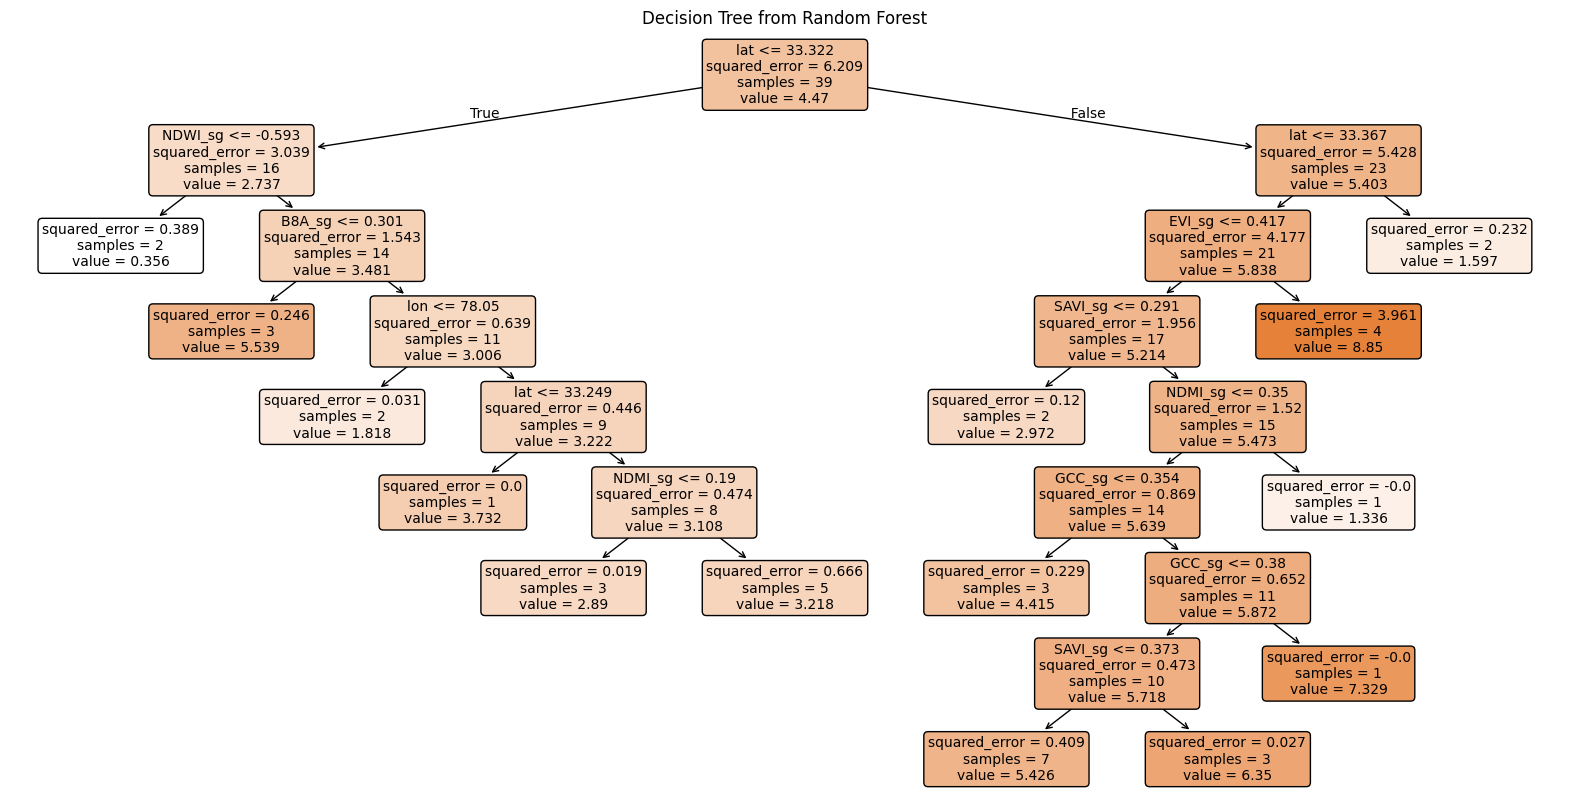

In [22]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

tree_to_plot = best_model.estimators_[0]

plt.figure(figsize=(20, 10))
plot_tree(tree_to_plot, feature_names=X_train.columns, filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree from Random Forest")
plt.show()

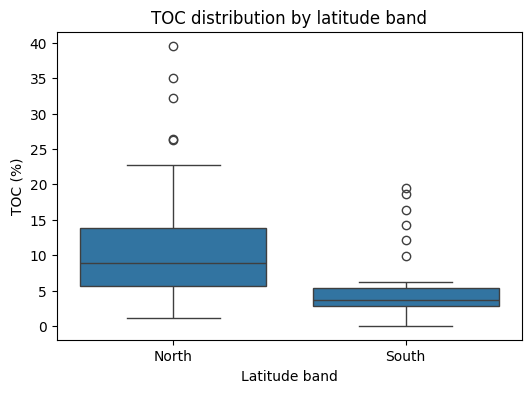

In [23]:
import numpy as np
import seaborn as sns

lat_split = X_test1["lat"].median()
X_test1["lat_band"] = np.where(X_test1["lat"] <= lat_split, "South", "North")

plt.figure(figsize=(6, 4))
sns.boxplot(x="lat_band", y="TOC_percent", data=X_test1)
plt.xlabel("Latitude band")
plt.ylabel("TOC (%)")
plt.title("TOC distribution by latitude band")
plt.show()

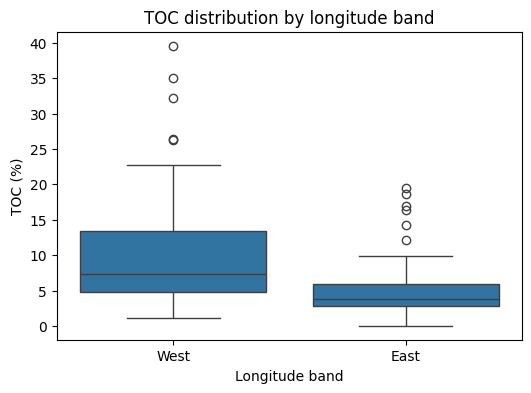

In [24]:
import numpy as np

lon_split = X_test1["lon"].median()
X_test1["lon_band"] = np.where(X_test1["lon"] <= lon_split, "West", "East")

plt.figure(figsize=(6, 4))
sns.boxplot(x="lon_band", y="TOC_percent", data=X_test1)
plt.xlabel("Longitude band")
plt.ylabel("TOC (%)")
plt.title("TOC distribution by longitude band")
plt.show()

In [25]:
print(list(X_train.columns))

['lon', 'lat', 'NDVI_sg', 'EVI_sg', 'SAVI_sg', 'GCC_sg', 'NDMI_sg', 'NDWI_sg', 'B6_sg', 'B7_sg', 'B8A_sg', 'B12_sg']


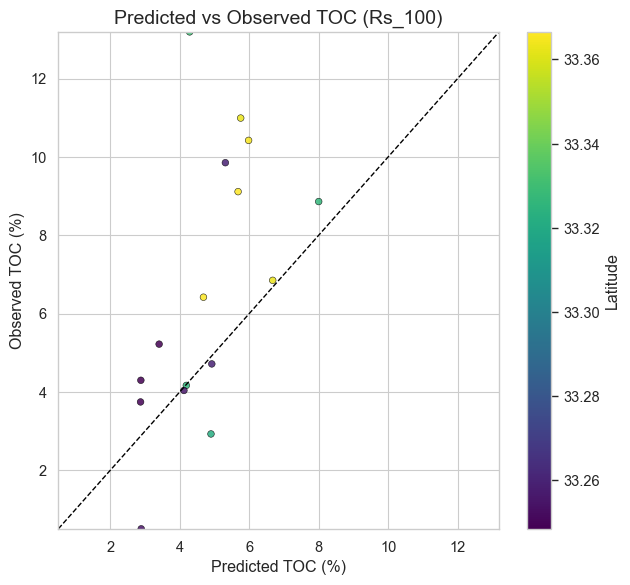

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

plot_df = pd.DataFrame({
    "Observed TOC (%)": y_test.values,
    "Predicted TOC (%)": pred_test,
    "Latitude": X_test['lat'].values
})

plot_df["Residual"] = plot_df["Observed TOC (%)"] - plot_df["Predicted TOC (%)"]

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

fig, ax = plt.subplots(figsize=(6.5, 6))

norm = Normalize(
    vmin=plot_df["Latitude"].min(),
    vmax=plot_df["Latitude"].max()
)

sns.scatterplot(
    data=plot_df,
    x="Predicted TOC (%)",
    y="Observed TOC (%)",
    hue="Latitude",
    palette="viridis",
    edgecolor="black",
    linewidth=0.4,
    alpha=0.85,
    legend=False,
    ax=ax
)

lims = [
    plot_df[["Observed TOC (%)", "Predicted TOC (%)"]].min().min(),
    plot_df[["Observed TOC (%)", "Predicted TOC (%)"]].max().max()
]

ax.plot(lims, lims, linestyle="--", color="black", linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_title("Predicted vs Observed TOC (Rs_100)", fontsize=14)
ax.set_xlabel("Predicted TOC (%)")
ax.set_ylabel("Observed TOC (%)")

sm = ScalarMappable(norm=norm, cmap="viridis")
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Latitude")

plt.tight_layout()
plt.show()

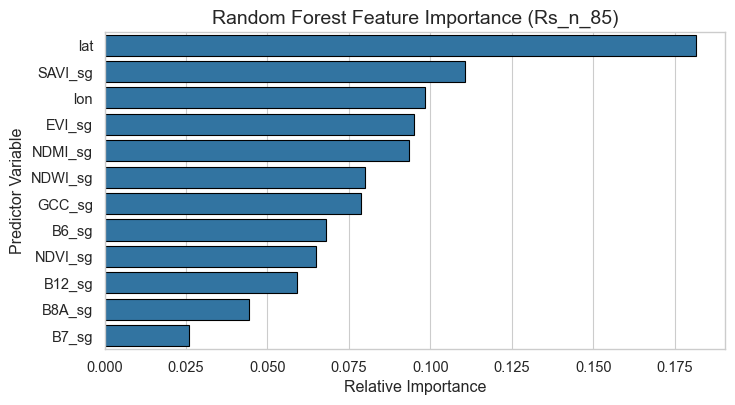

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

imp_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})

imp_df = (
    imp_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

fig, ax = plt.subplots(figsize=(7.5, max(4, 0.35 * len(imp_df))))

sns.barplot(
    data=imp_df,
    x="Importance",
    y="Feature",
    color="tab:blue",
    edgecolor="black",
    ax=ax
)

ax.set_title("Random Forest Feature Importance (Rs_n_85)", fontsize=14)
ax.set_xlabel("Relative Importance")
ax.set_ylabel("Predictor Variable")

plt.tight_layout()
plt.show()

Model without dropping outliers

In [28]:
X_test1.head()

,TOC_percent,lon,lat,NDVI_sg,EVI_sg,SAVI_sg,GCC_sg,NDMI_sg,NDWI_sg,B6_sg,B7_sg,B8A_sg,B12_sg,lat_band,lon_band
0,10.990,78.013973,33.362828,0.497980,0.305217,0.302951,0.363885,0.264767,-0.523740,0.215367,0.253655,0.283267,0.095543,North,West
1,3.217,78.013976,33.362737,0.477556,0.279599,0.281363,0.358505,0.254241,-0.541600,0.212986,0.248745,0.281855,0.093462,North,West
2,7.076,78.014295,33.362835,0.496463,0.341169,0.327427,0.360632,0.252019,-0.536332,0.251717,0.288962,0.317933,0.111600,North,West
3,6.224,78.014292,33.362925,0.537853,0.363936,0.342815,0.363035,0.247518,-0.570002,0.249364,0.292726,0.330014,0.105233,North,West
4,6.847,78.014506,33.362931,0.499561,0.373834,0.346212,0.364606,0.275880,-0.527997,0.256929,0.307336,0.342524,0.116105,North,West


In [29]:
X_test1.drop(['lat_band', 'lon_band'], axis=1, inplace=True)

In [30]:
from sklearn.model_selection import train_test_split, KFold

X2 = X_test1.drop(['TOC_percent'], axis=1)
y2 = X_test1['TOC_percent']

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

In [31]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

np.random.seed(42)

class SparrowSearchOptimizer:
    def __init__(self, obj_func, lb, ub, pop_size=25, max_iter=30):
        self.obj = obj_func
        self.lb = np.array(lb)
        self.ub = np.array(ub)
        self.dim = len(lb)
        self.pop = pop_size
        self.it = max_iter

    def optimize(self):
        Xp = np.random.uniform(self.lb, self.ub, (self.pop, self.dim))
        f = np.array([self.obj(x) for x in Xp])
        best_idx = np.argmin(f)
        best = Xp[best_idx].copy()
        best_f = f[best_idx]
        for t in range(self.it):
            r = np.random.rand()
            for i in range(self.pop):
                if i < self.pop * 0.2:
                    Xp[i] = Xp[i] * np.exp(-(i/(r+1e-9)))
                else:
                    Xp[i] = Xp[i] + np.random.randn(self.dim) * 0.01
                Xp[i] = np.clip(Xp[i], self.lb, self.ub)
            f = np.array([self.obj(x) for x in Xp])
            idx2 = np.argmin(f)
            if f[idx2] < best_f:
                best = Xp[idx2].copy()
                best_f = f[idx2]
        return best, best_f

def objective(params):
    n_estimators = int(params[0])
    max_depth = int(params[1])
    min_split = int(params[2])
    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_split,
        random_state=42
    )
    model.fit(X_train2, y_train2)
    preds2 = model.predict(X_test2)
    return mean_absolute_error(y_test2, preds2)

lb2 = [50, 3, 2]
ub2 = [400, 20, 10]

ssa = SparrowSearchOptimizer(objective, lb2, ub2, pop_size=25, max_iter=25)
best_params2, best_score2 = ssa.optimize()

best_model2 = RandomForestRegressor(
    n_estimators=int(best_params2[0]),
    max_depth=int(best_params2[1]),
    min_samples_split=int(best_params2[2]),
    oob_score=True,
    bootstrap=True,
    random_state=42
)

best_model2.fit(X_train2, y_train2)
pred_test2 = best_model2.predict(X_test2)

In [32]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

best_model2.fit(X_train2, y_train2)

pred_train2 = best_model2.predict(X_train2)
pred_test2 = best_model2.predict(X_test2)

r2_train = r2_score(y_train2, pred_train2)
r2_test = r2_score(y_test2, pred_test2)

mae = mean_absolute_error(y_test2, pred_test2)
rmse = np.sqrt(mean_squared_error(y_test2, pred_test2))

print("R2 train:", r2_train)
print("R2 test:", r2_test)
print("MAE:", mae)
print("RMSE:", rmse)

R2 train: 0.7728638484263757
R2 test: -0.2641864911858971
MAE: 8.302035228015974
RMSE: 11.737948815584303


In [33]:
oob_score = best_model2.oob_score_
print(f'Out-of-Bag Score: {oob_score}')

Out-of-Bag Score: -0.11434530851812053


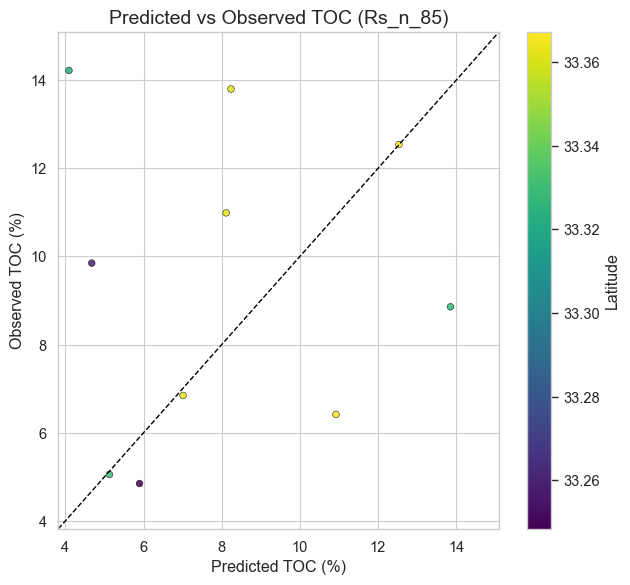

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

plot_df = pd.DataFrame({
    "Observed TOC (%)": y_test2.values,
    "Predicted TOC (%)": pred_test2,
    "Latitude": X_test2['lat'].values
})

plot_df["Residual"] = plot_df["Observed TOC (%)"] - plot_df["Predicted TOC (%)"]

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

fig, ax = plt.subplots(figsize=(6.5, 6))

norm = Normalize(
    vmin=plot_df["Latitude"].min(),
    vmax=plot_df["Latitude"].max()
)

sns.scatterplot(
    data=plot_df,
    x="Predicted TOC (%)",
    y="Observed TOC (%)",
    hue="Latitude",
    palette="viridis",
    edgecolor="black",
    linewidth=0.4,
    alpha=0.85,
    legend=False,
    ax=ax
)

lims = [
    plot_df[["Predicted TOC (%)"]].min().min(),
    plot_df[["Predicted TOC (%)"]].max().max()
]

ax.plot(lims, lims, linestyle="--", color="black", linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_title("Predicted vs Observed TOC (Rs_n_85)", fontsize=14)
ax.set_xlabel("Predicted TOC (%)")
ax.set_ylabel("Observed TOC (%)")

sm = ScalarMappable(norm=norm, cmap="viridis")
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Latitude")

plt.tight_layout()
plt.show()

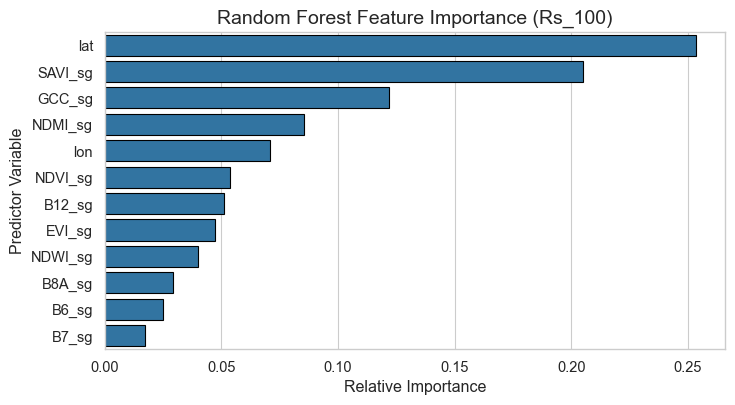

In [35]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

imp_df = pd.DataFrame({
    "Feature": X2.columns,
    "Importance": best_model2.feature_importances_
})

imp_df = (
    imp_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

fig, ax = plt.subplots(figsize=(7.5, max(4, 0.35 * len(imp_df))))

sns.barplot(
    data=imp_df,
    x="Importance",
    y="Feature",
    color="tab:blue",
    edgecolor="black",
    ax=ax
)

ax.set_title("Random Forest Feature Importance (Rs_100)", fontsize=14)
ax.set_xlabel("Relative Importance")
ax.set_ylabel("Predictor Variable")

plt.tight_layout()
plt.show()

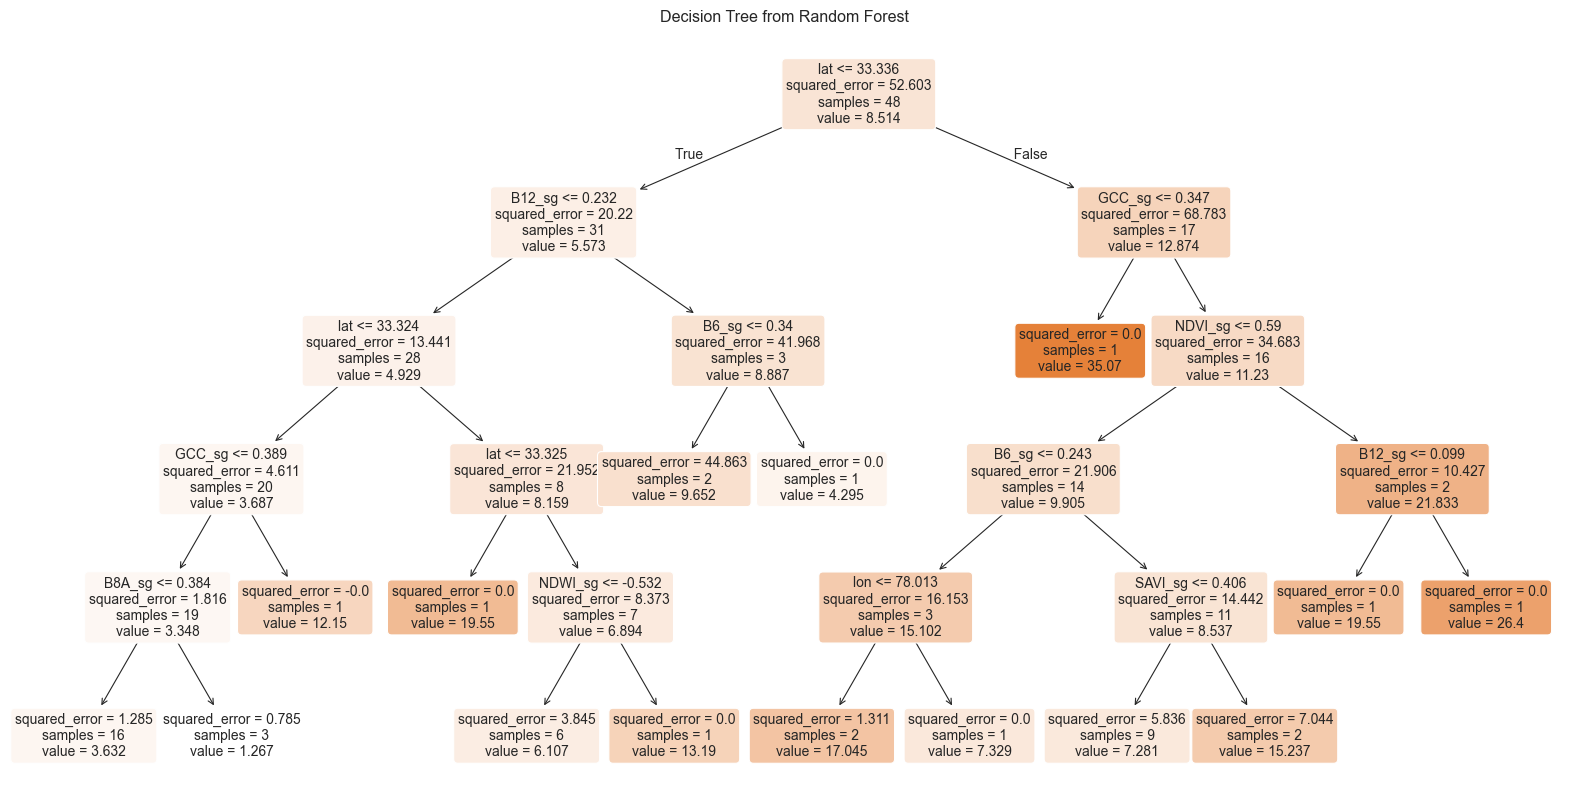

In [36]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

tree_to_plot = best_model2.estimators_[3]

plt.figure(figsize=(20, 10))
plot_tree(tree_to_plot, feature_names=X_train2.columns, filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree from Random Forest")
plt.show()

In [37]:
import numpy as np
import pandas as pd

output_df = merged.loc[
    X_test.index,
    ["lat", "lon", "TOC_percent"]
].copy()

output_df = output_df.rename(columns={"TOC_percent": "Observed_TOC"})

output_df["Predicted_TOC"] = pred_test
output_df["Error"] = output_df["Observed_TOC"] - output_df["Predicted_TOC"]
output_df["Absolute_Error"] = np.abs(output_df["Error"])

output_df = output_df.reset_index(drop=True)

output_df

output_df.to_csv(
    "/Users/aditiiyer/Documents/Thesis/test_set_predictions_model_Rs_n_75.csv",
    index=False
)
import pandas as pd
import numpy as np

output_df1 = merged.loc[
    X_test2.index,
    ["lat", "lon", "TOC_percent"]
].copy()

output_df1 = output_df1.rename(columns={"TOC_percent": "Observed_TOC"})

output_df1["Predicted_TOC"] = pred_test2
output_df1["Error"] = output_df["Observed_TOC"] - output_df1["Predicted_TOC"]
output_df1["Absolute_Error"] = np.abs(output_df1["Error"])

output_df1 = output_df.reset_index(drop=True)

output_df1
output_df1.to_csv(
    "/Users/aditiiyer/Documents/Thesis/test_set_predictions_model_Rs_100.csv",
    index=False
)